Lab 8 — KNN Pumpkin Seed Classification
Name: Joonsuh Kim,Wall

Source: Instructor's knn_pumpkin_seeds_3-16-2026.py from Canvas.
Algorithm: K-Nearest Neighbors (KNN).

Purpose:
This example predicts whether a pumpkin seed belongs to the
Cercevelik or Urgup_Sivrisi variety using six measurements.

The instructor's code generates 250 synthetic samples.
These are simulated measurements, not measurements collected
from real seeds.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Use the same random seed as the instructor
np.random.seed(42)

# Generate 125 samples of the first variety
n1 = 125

cercevelik = pd.DataFrame({
    "Area": np.random.normal(55000, 5000, n1),
    "Perimeter": np.random.normal(850, 40, n1),
    "Major_Axis": np.random.normal(310, 20, n1),
    "Minor_Axis": np.random.normal(220, 15, n1),
    "Roundness": np.random.normal(0.88, 0.04, n1),
    "Compactness": np.random.normal(0.72, 0.03, n1),
    "Class": "Cercevelik"
})

# Generate 125 samples of the second variety
n2 = 125

urgup = pd.DataFrame({
    "Area": np.random.normal(72000, 6000, n2),
    "Perimeter": np.random.normal(1050, 50, n2),
    "Major_Axis": np.random.normal(420, 25, n2),
    "Minor_Axis": np.random.normal(210, 15, n2),
    "Roundness": np.random.normal(0.75, 0.05, n2),
    "Compactness": np.random.normal(0.55, 0.04, n2),
    "Class": "Urgup_Sivrisi"
})

# Combine the two varieties
df = pd.concat([cercevelik, urgup], ignore_index=True)

print("Total samples:", len(df))
print("Number of features:", df.shape[1] - 1)

display(df.head(10))
print(df["Class"].value_counts())

Total samples: 250
Number of features: 6


,Area,Perimeter,Major_Axis,Minor_Axis,Roundness,Compactness,Class
0,57483.570765,937.618225,284.782321,208.489787,0.917047,0.704664,Cercevelik
1,54308.678494,810.378547,328.357239,233.084810,0.956377,0.690312,Cercevelik
2,58238.442691,827.348091,352.443124,222.750130,0.824057,0.716226,Cercevelik
3,62615.149282,853.986055,330.649305,252.847044,0.902519,0.721672,Cercevelik
4,53829.233126,829.860974,279.612601,207.875526,0.853974,0.752826,Cercevelik
5,53829.315215,787.973463,300.315319,207.404172,0.860515,0.669226,Cercevelik
6,62896.064078,852.742519,335.338223,211.009110,0.856304,0.765887,Cercevelik
7,58837.173646,807.507851,295.846611,188.141564,0.845440,0.715260,Cercevelik
8,52652.628070,868.943697,318.876389,212.113675,0.881941,0.707194,Cercevelik
9,57712.800218,813.223031,325.492681,208.613010,0.846762,0.689637,Cercevelik


Class
Cercevelik       125
Urgup_Sivrisi    125
Name: count, dtype: int64


Exploring the data

I compare the average measurements of the two varieties and plot
area against roundness. This helps show how the simulated groups
differ in size and shape.

The colors represent the known variety labels. The plot displays
existing classes; it does not create new clusters.

,Area,Perimeter,Major_Axis,Minor_Axis,Roundness,Compactness
Class,,,,,,
Cercevelik,54638.766,852.696,311.357,219.465,0.880,0.716
Urgup_Sivrisi,72687.463,1057.370,425.183,210.227,0.747,0.560


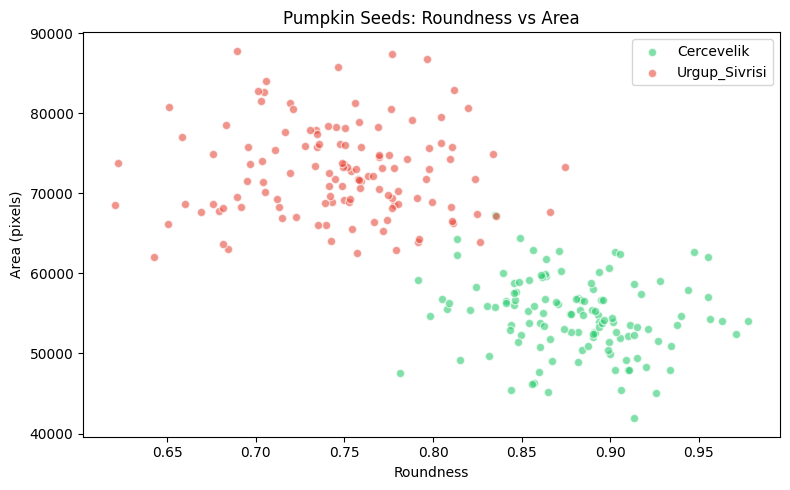

In [ ]:
# Compare average measurements by variety
display(df.groupby("Class").mean().round(3))

# Plot two features using the known class labels
colors = {
    "Cercevelik": "#2ecc71",
    "Urgup_Sivrisi": "#e74c3c"
}

plt.figure(figsize=(8, 5))

for seed_type, color in colors.items():
    subset = df[df["Class"] == seed_type]

    plt.scatter(
        subset["Roundness"],
        subset["Area"],
        color=color,
        label=seed_type,
        alpha=0.6,
        edgecolors="white"
    )

plt.xlabel("Roundness")
plt.ylabel("Area (pixels)")
plt.title("Pumpkin Seeds: Roundness vs Area")
plt.legend()
plt.tight_layout()
plt.show()

Preparing the data

The six measurements are the input features, and Class is the
target label. I use 80% of the samples for training and 20% for
testing, keeping the same class proportions in both sets.

KNN uses distances, so features with large numerical values could
dominate the calculation. I standardize the features using only
the training data, then apply the same transformation to the test
data.

In [ ]:
# Separate input features and target labels
X = df.drop("Class", axis=1)
y = df["Class"]

# Use the same split as the instructor
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Learn scaling parameters from training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 200
Test samples: 50


Training and evaluating KNN

I first use K=5. For each test seed, KNN finds the five nearest
training samples and predicts the variety with the most votes.

Accuracy shows the fraction of correct predictions. In the
confusion matrix, rows show actual varieties and columns show
predicted varieties. Values outside the diagonal are mistakes.

Test accuracy with K=5: 100.00%

Classification report:
               precision    recall  f1-score   support

   Cercevelik       1.00      1.00      1.00        25
Urgup_Sivrisi       1.00      1.00      1.00        25

     accuracy                           1.00        50
    macro avg       1.00      1.00      1.00        50
 weighted avg       1.00      1.00      1.00        50



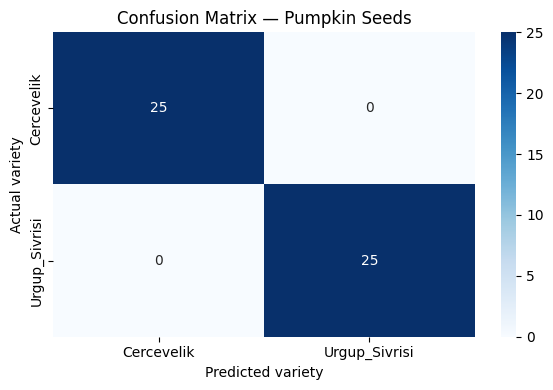

In [ ]:
# Train the initial model with five neighbors
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Predict the varieties of the test samples
y_pred = knn.predict(X_test_scaled)

# Evaluate the predictions
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy with K=5: {accuracy:.2%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

# Keep labels in the same order as the model's classes
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=knn.classes_
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=knn.classes_,
    yticklabels=knn.classes_
)

plt.xlabel("Predicted variety")
plt.ylabel("Actual variety")
plt.title("Confusion Matrix — Pumpkin Seeds")
plt.tight_layout()
plt.show()

Comparing K values

I reproduce the instructor's comparison of K values from 1 to 25.
The original example compares them using the same test set.

Because the test results are used to select K, the selected score
is not an independent final evaluation. For a new analysis,
validation or cross-validation within the training data should
be used to choose K.

If several K values have the same highest score, the code selects
the first one. This does not mean it is uniquely the best.

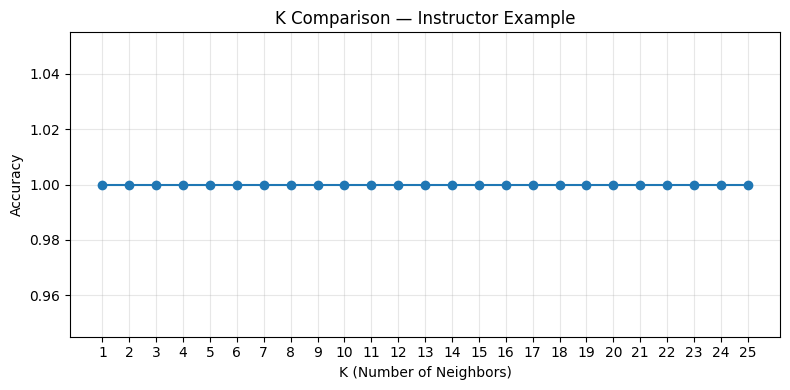

Selected K: 1
Highest observed accuracy: 100.00%


In [ ]:
# Reproduce the instructor's K comparison
k_values = range(1, 26)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, pred)

    accuracies.append(acc)

# Plot the results
plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker="o")

plt.xlabel("K (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.title("K Comparison — Instructor Example")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Select the first K with the highest observed score
best_k = list(k_values)[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print("Selected K:", best_k)
print(f"Highest observed accuracy: {best_accuracy:.2%}")

Predicting a new seed

I use the selected K to classify one additional seed from the
instructor's example. Its measurements are transformed using the
same scaler fitted to the training data.

For this KNN model, the probability values are the proportions
of neighbors belonging to each variety. A value of 100% does not
guarantee that the predicted variety is correct.

In [ ]:
# Train a model using the K selected above
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

# New seed measurements from the instructor's example
new_seed = pd.DataFrame({
    "Area": [60000],
    "Perimeter": [920],
    "Major_Axis": [350],
    "Minor_Axis": [215],
    "Roundness": [0.82],
    "Compactness": [0.65]
})

display(new_seed)

# Apply the same training scaler
new_seed_scaled = scaler.transform(new_seed)

prediction = final_model.predict(new_seed_scaled)
probabilities = final_model.predict_proba(new_seed_scaled)

print("Predicted variety:", prediction[0])

for class_name, probability in zip(
    final_model.classes_,
    probabilities[0]
):
    print(f"{class_name}: {probability:.1%}")

,Area,Perimeter,Major_Axis,Minor_Axis,Roundness,Compactness
0,60000,920,350,215,0.82,0.65


Predicted variety: Cercevelik
Cercevelik: 100.0%
Urgup_Sivrisi: 0.0%


Summary

I reproduced the instructor's KNN example to classify two pumpkin
seed varieties using six size and shape measurements. The code
generated 250 simulated samples. I used 200 for training and 50
for testing. I standardized the measurements before applying KNN.

With K=5, the model correctly classified all 50 test samples:
25 Cercevelik and 25 Urgup_Sivrisi seeds. This suggests that the
two groups are easy to distinguish in this simulated dataset.
However, it does not mean that the model would classify real
pumpkin seeds perfectly.

The original K comparison selected K=1 as the first value with
the highest score. Other values may share the same score, and
the test set was reused to choose K. Therefore, this comparison
does not provide an independent final evaluation of the selected
model.

The additional seed was predicted as Cercevelik. With K=1, the
100% neighbor-vote score means that its nearest training sample
was Cercevelik. It is not a guarantee that the prediction is correct.